# UPI Transactions 2024 - EDA

## 1. Import libraries and load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

In [2]:
df = pd.read_csv("upi_transactions_2024.csv")   # change the file name/path if needed
df.head()

,transaction id,timestamp,transaction type,merchant_category,amount (INR),transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,receiver_bank,device_type,network_type,fraud_flag,hour_of_day,day_of_week,is_weekend
0,TXN0000000001,2024-10-08 15:17:28,P2P,Entertainment,868,SUCCESS,26-35,18-25,Delhi,Axis,SBI,Android,4G,0,15,Tuesday,0
1,TXN0000000002,2024-04-11 06:56:00,P2M,Grocery,1011,SUCCESS,26-35,26-35,Uttar Pradesh,ICICI,Axis,iOS,4G,0,6,Thursday,0
2,TXN0000000003,2024-04-02 13:27:18,P2P,Grocery,477,SUCCESS,26-35,36-45,Karnataka,Yes Bank,PNB,Android,4G,0,13,Tuesday,0
3,TXN0000000004,2024-01-07 10:09:17,P2P,Fuel,2784,SUCCESS,26-35,26-35,Delhi,ICICI,PNB,Android,5G,0,10,Sunday,1
4,TXN0000000005,2024-01-23 19:04:23,P2P,Shopping,990,SUCCESS,26-35,18-25,Delhi,Axis,Yes Bank,iOS,WiFi,0,19,Tuesday,0


## 2. Basic information about the data

In [3]:
print("Rows, columns:", df.shape)
df.info()

Rows, columns: (250000, 17)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 17 columns):
 #   Column              Non-Null Count   Dtype 
---  ------              --------------   ----- 
 0   transaction id      250000 non-null  object
 1   timestamp           250000 non-null  object
 2   transaction type    250000 non-null  object
 3   merchant_category   250000 non-null  object
 4   amount (INR)        250000 non-null  int64 
 5   transaction_status  250000 non-null  object
 6   sender_age_group    250000 non-null  object
 7   receiver_age_group  250000 non-null  object
 8   sender_state        250000 non-null  object
 9   sender_bank         250000 non-null  object
 10  receiver_bank       250000 non-null  object
 11  device_type         250000 non-null  object
 12  network_type        250000 non-null  object
 13  fraud_flag          250000 non-null  int64 
 14  hour_of_day         250000 non-null  int64 
 15  day_of_week         250

In [4]:
# make column names simple: "amount (INR)" -> "amount_inr"
df.columns = (df.columns.str.strip().str.lower()
              .str.replace(" ", "_").str.replace("(", "").str.replace(")", ""))
print(df.columns.tolist())

['transaction_id', 'timestamp', 'transaction_type', 'merchant_category', 'amount_inr', 'transaction_status', 'sender_age_group', 'receiver_age_group', 'sender_state', 'sender_bank', 'receiver_bank', 'device_type', 'network_type', 'fraud_flag', 'hour_of_day', 'day_of_week', 'is_weekend']


In [5]:
# Column names used below - change these if your columns are named differently
target = "fraud_flag"
amount = "amount_inr"
cat_cols = ["transaction_type", "merchant_category", "transaction_status",
            "sender_age_group", "sender_state", "sender_bank", "device_type", "network_type"]
cat_cols = [c for c in cat_cols if c in df.columns]   # keep only the ones that exist
print(cat_cols)

['transaction_type', 'merchant_category', 'transaction_status', 'sender_age_group', 'sender_state', 'sender_bank', 'device_type', 'network_type']


In [6]:
df.describe()

,amount_inr,fraud_flag,hour_of_day,is_weekend
count,250000.000000,250000.000000,250000.000000,250000.000000
mean,1311.756036,0.001920,14.681032,0.285348
std,1848.059224,0.043776,5.188304,0.451581
min,10.000000,0.000000,0.000000,0.000000
25%,288.000000,0.000000,11.000000,0.000000
50%,629.000000,0.000000,15.000000,0.000000
75%,1596.000000,0.000000,19.000000,1.000000
max,42099.000000,1.000000,23.000000,1.000000


## 3. Data cleaning checks

In [7]:
# Missing values
df.isnull().sum()

transaction_id        0
timestamp             0
transaction_type      0
merchant_category     0
amount_inr            0
transaction_status    0
sender_age_group      0
receiver_age_group    0
sender_state          0
sender_bank           0
receiver_bank         0
device_type           0
network_type          0
fraud_flag            0
hour_of_day           0
day_of_week           0
is_weekend            0
dtype: int64

In [8]:
# Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


## 4. Fraud vs non-fraud (target column)

fraud_flag
0    249520
1       480
Name: count, dtype: int64
Fraud percentage: 0.192 %


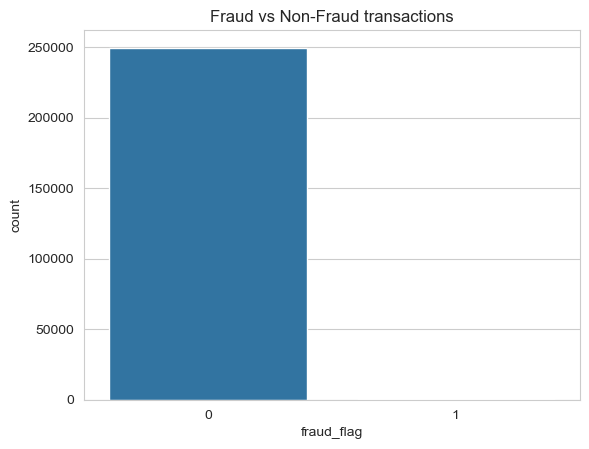

In [9]:
print(df[target].value_counts())
print("Fraud percentage:", round(df[target].mean() * 100, 3), "%")

sns.countplot(x=target, data=df)
plt.title("Fraud vs Non-Fraud transactions")
plt.show()

The dataset is **imbalanced** - very few fraud cases compared to normal transactions. This matters later when we train a model.

## 5. Transaction amount

In [10]:
df[amount].describe()

count    250000.000000
mean       1311.756036
std        1848.059224
min          10.000000
25%         288.000000
50%         629.000000
75%        1596.000000
max       42099.000000
Name: amount_inr, dtype: float64

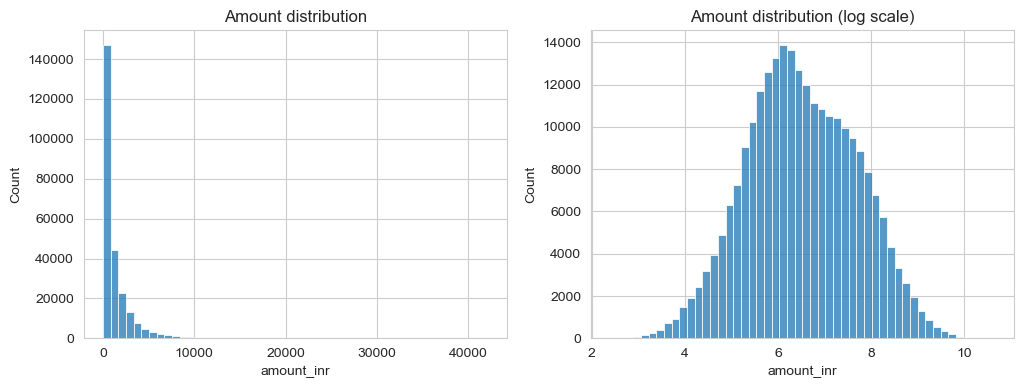

In [11]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.histplot(df[amount], bins=50)
plt.title("Amount distribution")

plt.subplot(1, 2, 2)
sns.histplot(np.log1p(df[amount]), bins=50)   # log makes skewed data easier to read
plt.title("Amount distribution (log scale)")

plt.show()

                   mean  median    max
fraud_flag                            
0           1311.395391   629.0  42099
1           1499.231250   618.5  17718


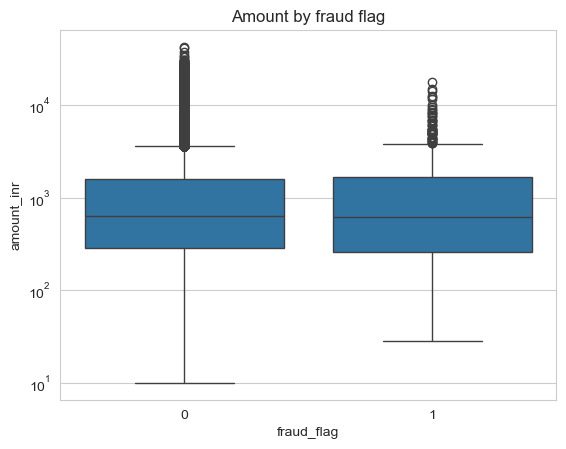

In [12]:
# Amount: fraud vs non-fraud
print(df.groupby(target)[amount].agg(["mean", "median", "max"]))

sns.boxplot(x=target, y=amount, data=df)
plt.yscale("log")
plt.title("Amount by fraud flag")
plt.show()

## 6. Time analysis

In [13]:
df["timestamp"] = pd.to_datetime(df["timestamp"])
df["month"] = df["timestamp"].dt.month
df["hour"] = df["timestamp"].dt.hour
df["day_name"] = df["timestamp"].dt.day_name()
df["timestamp"].min(), df["timestamp"].max()

(Timestamp('2024-01-01 00:05:10'), Timestamp('2024-12-30 23:55:40'))

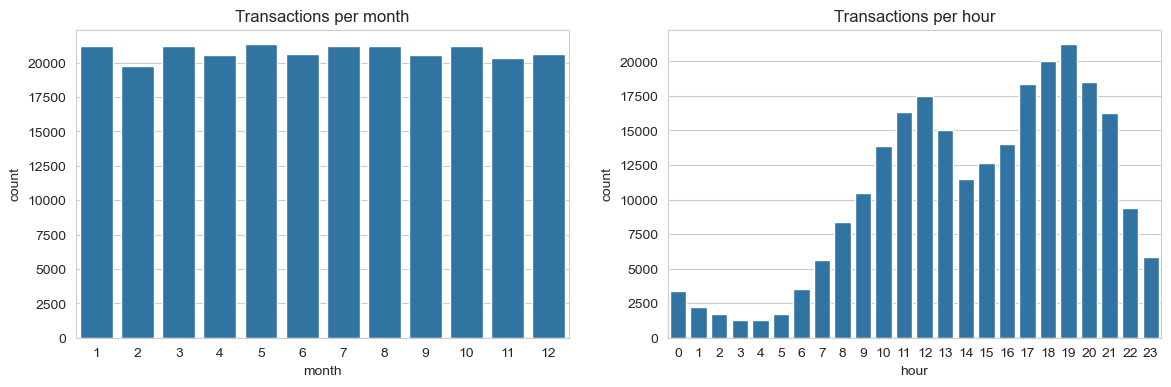

In [14]:
plt.figure(figsize=(14, 4))

plt.subplot(1, 2, 1)
sns.countplot(x="month", data=df)
plt.title("Transactions per month")

plt.subplot(1, 2, 2)
sns.countplot(x="hour", data=df)
plt.title("Transactions per hour")

plt.show()

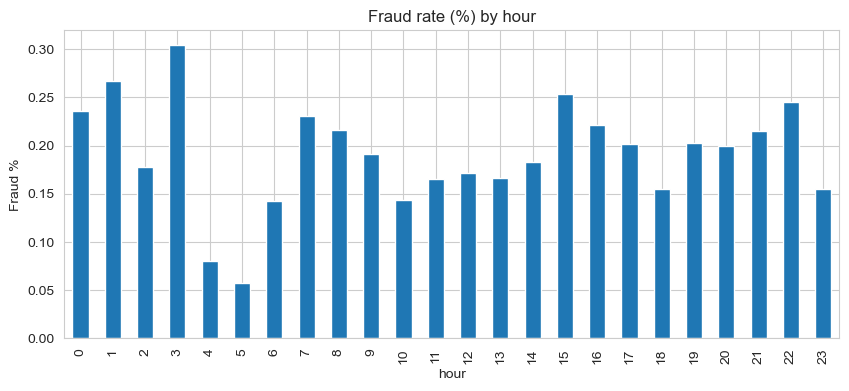

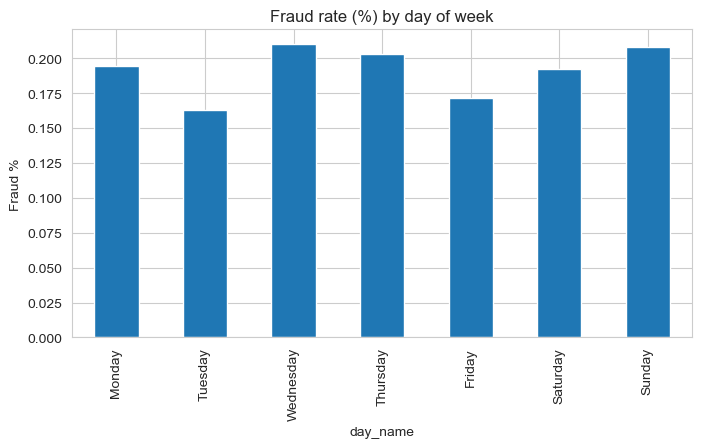

In [15]:
# Fraud rate (%) by hour and by day
fraud_by_hour = df.groupby("hour")[target].mean() * 100
fraud_by_hour.plot(kind="bar", figsize=(10, 4))
plt.title("Fraud rate (%) by hour")
plt.ylabel("Fraud %")
plt.show()

days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
fraud_by_day = df.groupby("day_name")[target].mean().reindex(days) * 100
fraud_by_day.plot(kind="bar", figsize=(8, 4))
plt.title("Fraud rate (%) by day of week")
plt.ylabel("Fraud %")
plt.show()

## 7. Categorical columns

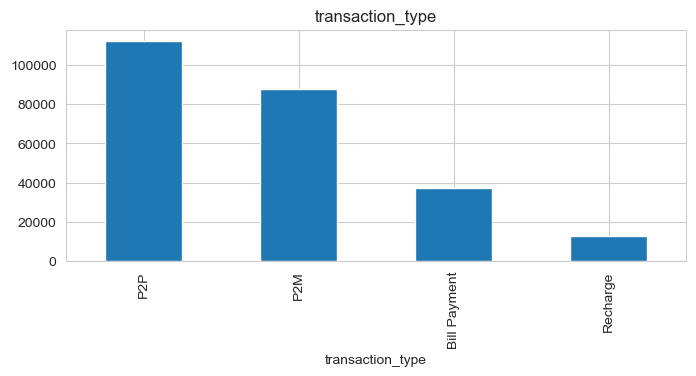

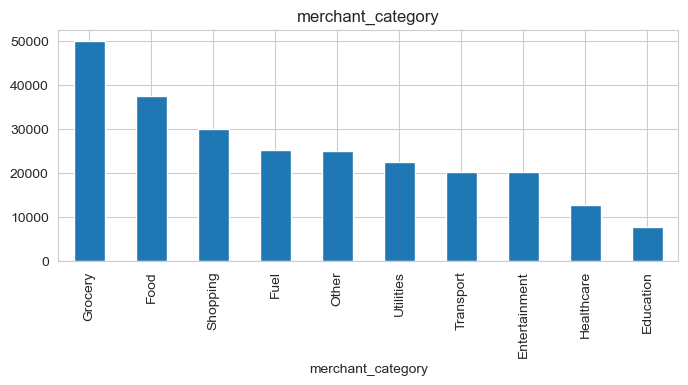

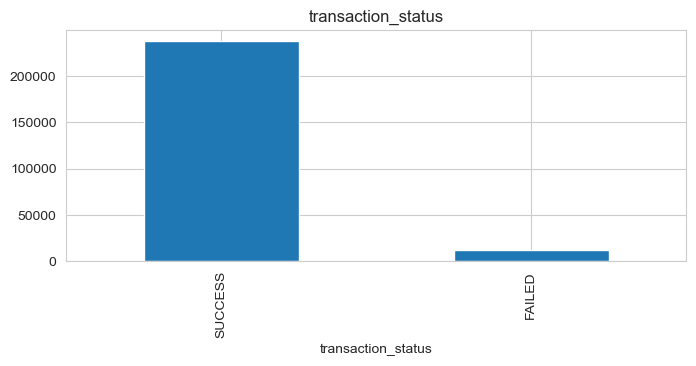

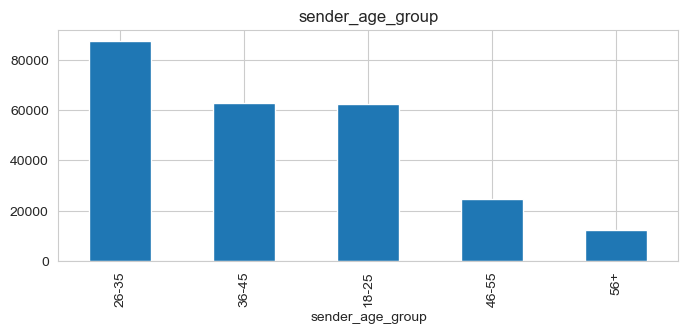

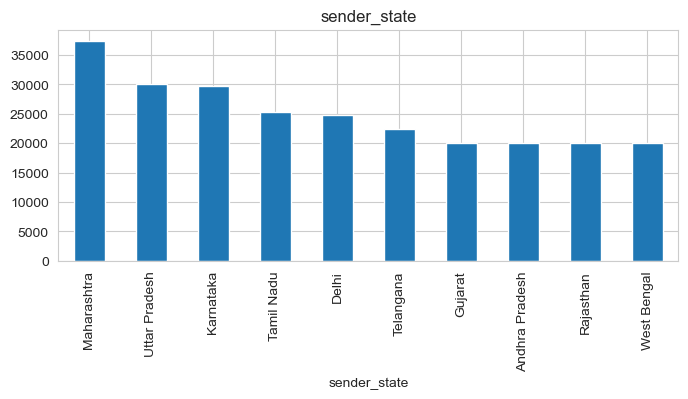

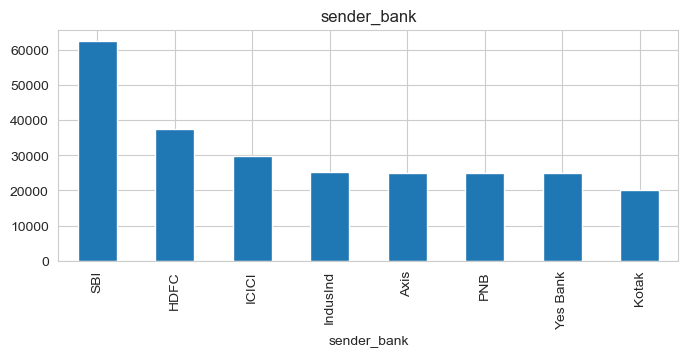

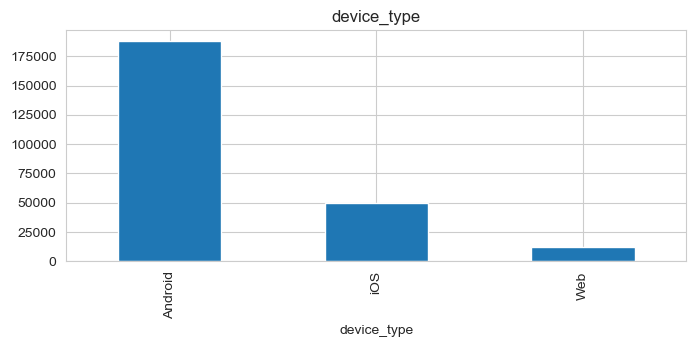

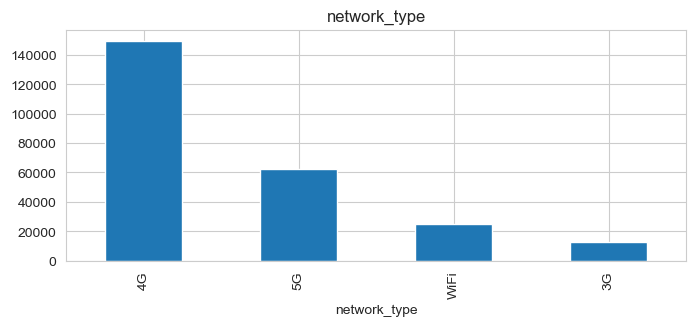

In [16]:
# Number of transactions in each category
for col in cat_cols:
    plt.figure(figsize=(8, 3))
    df[col].value_counts().plot(kind="bar")
    plt.title(col)
    plt.show()

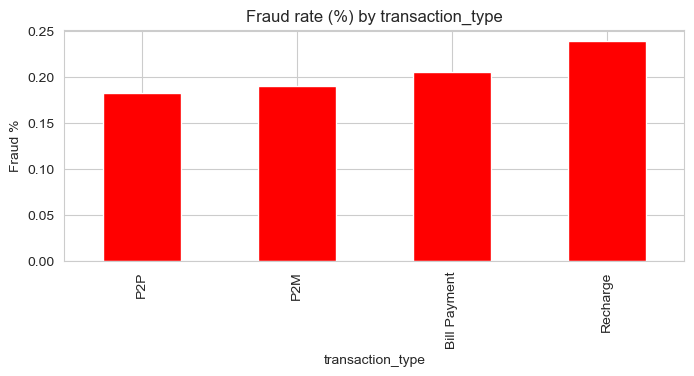

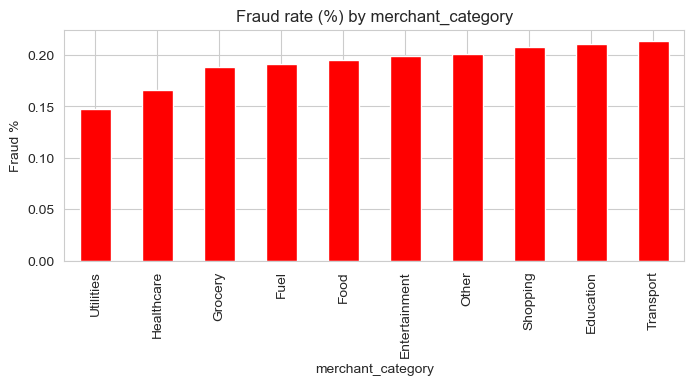

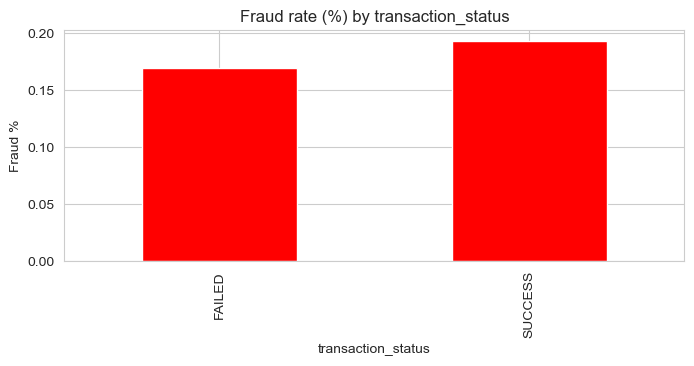

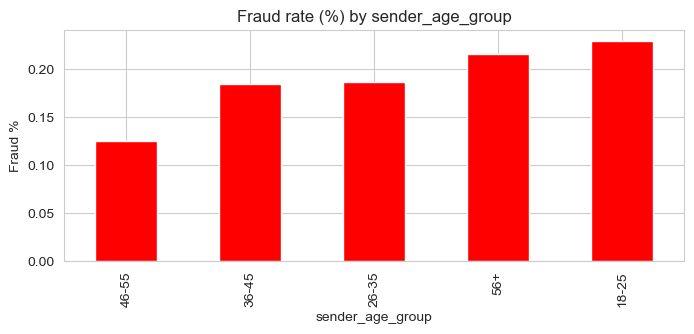

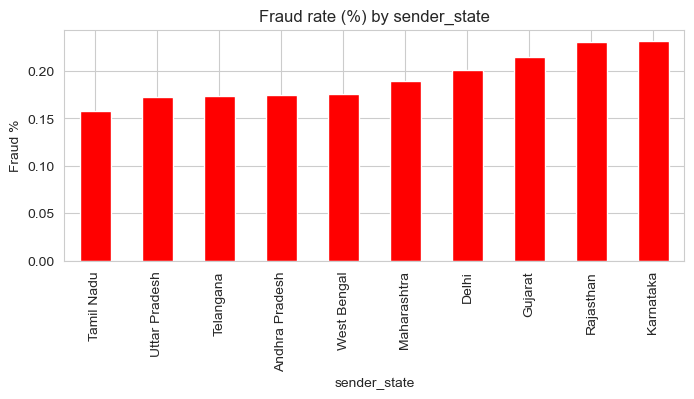

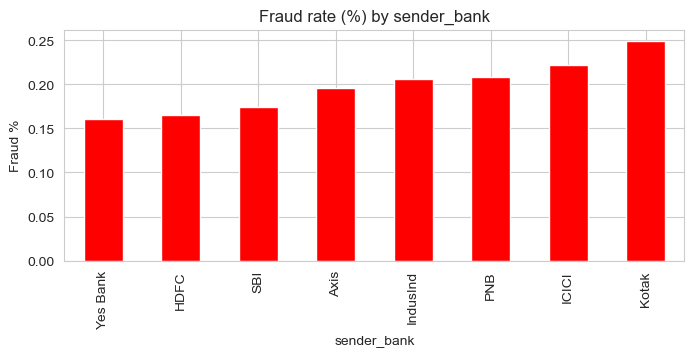

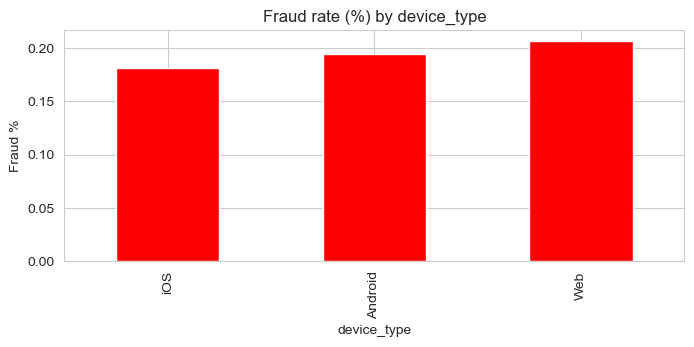

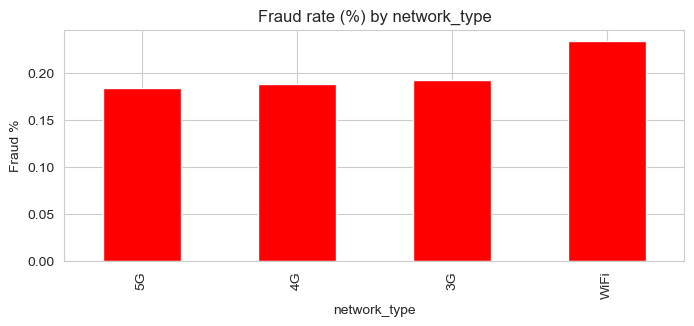

In [17]:
# Fraud rate (%) in each category
for col in cat_cols:
    rate = df.groupby(col)[target].mean() * 100
    plt.figure(figsize=(8, 3))
    rate.sort_values().plot(kind="bar", color="red")
    plt.title("Fraud rate (%) by " + col)
    plt.ylabel("Fraud %")
    plt.show()

## 8. Correlation

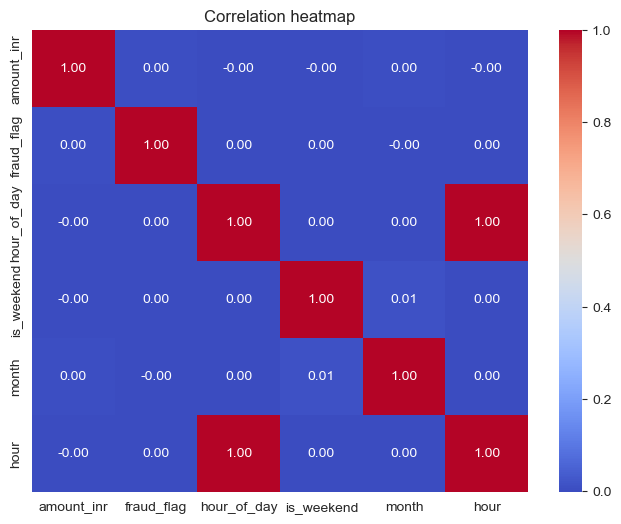

In [18]:
num_df = df.select_dtypes(include="number")
plt.figure(figsize=(8, 6))
sns.heatmap(num_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap")
plt.show()

## 9. Conclusions
Write your observations here after running the notebook:
- Fraud percentage in the dataset:
- Does fraud happen more for high or low amounts?
- Which hours/days have more fraud?
- Which categories (bank, state, device, etc.) have higher fraud?
- Any missing values or duplicates to fix in preprocessing?